<a href="https://colab.research.google.com/github/brittanybee-alt/Updated-Capstone-Project---Brittany-Barrion/blob/main/BB_DC_Capstone_Two_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone Two: Modeling
## Where You Grow Up Matters: Predicting Adult Income for Low-Income Children in the DC Region

**Project question:** Which neighborhood characteristics best predict adult income for children raised in low-income families in the DC metro area?

### Data Source
All data comes from **The Opportunity Atlas** (Opportunity Insights and the U.S. Census Bureau):

**[The Opportunity Atlas: household income at age 35 for children raised in low-income families, DC region](https://www.opportunityatlas.org/?%7B%22mapping%22%3A%22kfr%22%2C%22dataToggles%22%3A%7B%22parentIncome%22%3A%22p25%22%2C%22childRace%22%3A%22rP%22%2C%22childGender%22%3A%22gP%22%2C%22cohortTimeline%22%3A%22e%22%7D%2C%22compareDataToggles%22%3A%7B%22parentIncome%22%3A%22pall%22%2C%22childRace%22%3A%22rP%22%2C%22childGender%22%3A%22gP%22%2C%22cohortTimeline%22%3A%22e%22%7D%2C%22selectedChapterId%22%3A%22chapter1%22%2C%22compareFeatures%22%3A%22loc%22%2C%22selectedFeatureByID%22%3A11001010200%2C%22filters%22%3A%5B%5D%2C%22mode%22%3A%22standardMode%22%2C%22mapBounds%22%3A%5B%5B-77.29824387656735%2C38.72686964592006%5D%2C%5B-76.79125493105334%2C39.0687791383437%5D%5D%2C%22floatingPanelIsMinimized%22%3Afalse%2C%22showStoryMarkers%22%3Atrue%2C%22showHistogram%22%3Afalse%2C%22propertyShownOnMap%22%3A%22kfr_rP_gP_p25_e%22%7D)**

Two Census-tract-level files were downloaded from this map view (`shown_tract_kfr_rP_gP_p25.csv` for the target and `shown_tract_allCharacteristics.csv` for the neighborhood characteristics), then cleaned, explored and preprocessed in the earlier notebooks.

### Goal
Build two to three different models and identify the best one.

**Input:** the four files saved by the Pre-processing notebook in `data/processed/`:
- `X_train.csv` (601 tracts × 11 features) and `y_train.csv`
- `X_test.csv` (151 tracts × 11 features) and `y_test.csv`

The 11 features are the 9 numeric neighborhood features selected in EDA (standardized) plus the `state_MD` and `state_VA` dummies (DC is the baseline).

**Steps (following the outline):**
1. Fit the models with the training dataset
2. Review model outcomes and iterate over additional models as needed
3. Identify the final model

### Review questions

**Does my data involve a time series or forecasting? If so, am I splitting the train and test data appropriately?**
No. Each row is a different Census tract, measured once, so this is **cross-sectional** data, not a time series. There's no future to forecast and no risk of training on later dates to predict earlier ones, so a **random** train/test split is appropriate. That split was done in Pre-processing (80/20, stratified by state).

*One caveat:* neighboring tracts tend to be similar, so a random split puts some next-door neighbors of training tracts into the test set. This may make test scores slightly optimistic for brand-new areas. I'll note it as a limitation in the final report.

**Is my response variable continuous or categorical?**
**Continuous.** `income_age35` is a dollar amount (about \$19,500 to \$69,200), so this is a **regression** problem. Classification metrics such as accuracy, recall, precision and F1 (mentioned in the outline's hint) don't apply. I use regression metrics instead.

### Metrics used to choose the final model
| Metric | What it means | Better when |
|---|---|---|
| **RMSE** (root mean squared error), *primary metric* | Typical prediction error in dollars. Large misses count extra. | Lower |
| **MAE** (mean absolute error) | Average size of a miss in dollars. Less affected by a few big misses. | Lower |
| **R²** | Share of the variation in adult income the model explains (0 = none, 1 = all) | Higher |

**How models are compared:** all choices (hyperparameters and the final model) are made with **5-fold cross-validation on the training set only**. The test set is used **once**, at the end, to report how the chosen model does on tracts it has never seen.

### Setup
**In Google Colab:** upload the four CSV files into a `data/processed` folder (Files panel on the left), then run the cells below.

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.inspection import permutation_importance

sns.set_theme(style='whitegrid')
for folder in ['figures', 'models', 'data/processed']:
    os.makedirs(folder, exist_ok=True)

X_train = pd.read_csv('/content/X_train.csv')
X_test = pd.read_csv('/content/X_test.csv')
y_train = pd.read_csv('/content/y_train.csv').squeeze()
y_test = pd.read_csv('/content/y_test.csv').squeeze()

print('X_train:', X_train.shape, ' y_train:', y_train.shape)
print('X_test: ', X_test.shape, ' y_test: ', y_test.shape)
X_train.head()

X_train: (601, 11)  y_train: (601,)
X_test:  (151, 11)  y_test:  (151,)


,median_rent,median_hh_income_1990,poverty_rate,frac_nonwhite,frac_foreign_born,frac_single_parents,log_pop_density,frac_short_commute,census_response_rate,state_MD,state_VA
0,-0.616210,-0.997832,0.354103,0.688651,1.340431,0.483537,0.478580,0.228098,-1.252177,0,1
1,-0.304854,-0.393588,-0.010351,0.229797,1.826550,-0.422985,0.562251,-0.043934,-1.364340,0,1
2,2.010229,1.680489,-0.798782,-1.257560,-0.387334,-1.146397,-1.089157,0.073271,1.565921,0,1
3,-0.889065,0.778918,-0.491764,0.358360,0.758142,-0.332720,-0.827357,-0.271110,0.430269,1,0
4,0.091874,-0.051893,-0.618122,-0.539141,-0.157449,-0.267814,0.890262,-0.420149,-0.340852,0,1


### Cross-validation setup
Every model is scored the same way: **5-fold cross-validation** with the same folds (`random_state=42`). The training set is split into 5 parts, and each model is trained on 4 parts and scored on the 5th, five times over. Averaging the 5 scores gives a fairer estimate than a single split, and the spread (standard deviation) shows how stable the model is.

In [2]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2'}

cv_results = {}

def evaluate_cv(name, model):
    """Score a model with 5-fold CV on the training set and store the results."""
    start = time.time()
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_results[name] = {
        'cv_rmse': -scores['test_rmse'].mean(),
        'cv_rmse_std': scores['test_rmse'].std(),
        'cv_mae': -scores['test_mae'].mean(),
        'cv_r2': scores['test_r2'].mean(),
        'fit_seconds': (time.time() - start) / 5,
    }
    r = cv_results[name]
    print(f"{name}: RMSE ${r['cv_rmse']:,.0f} (± {r['cv_rmse_std']:,.0f}), "
          f"MAE ${r['cv_mae']:,.0f}, R² {r['cv_r2']:.3f}")

## Step 1: Fit the Models with the Training Dataset

### Baseline: predict the average
A useful model has to beat a "model" that ignores the neighborhood entirely and predicts the training average (about \$36,700) for every tract. This sets the bar.

In [3]:
evaluate_cv('Baseline (mean)', DummyRegressor(strategy='mean'))

Baseline (mean): RMSE $9,670 (± 548), MAE $8,013, R² -0.016


### Model 1: Linear Regression
**Why this model:** linear regression is the simplest regression model and the easiest to explain. Each coefficient says how much adult income changes when a feature goes up by one standard deviation (because the features were standardized), holding the others constant. EDA showed mostly straight-line relationships with the target, and the VIF check removed the worst multicollinearity, so it's a reasonable starting point.

In [4]:
evaluate_cv('Linear Regression', LinearRegression())

Linear Regression: RMSE $5,344 (± 719), MAE $3,934, R² 0.690


#### Model 1 variations: Ridge and Lasso (regularized linear regression)
Ridge and Lasso add a penalty that shrinks the coefficients. This can help when features still overlap, and Lasso can shrink weak features all the way to zero. The penalty strength, **alpha**, is a hyperparameter, so I tune it with `GridSearchCV`, which tries each value with the same 5-fold cross-validation.

In [5]:
ridge_search = GridSearchCV(Ridge(), {'alpha': np.logspace(-2, 3, 30)},
                            cv=cv, scoring='neg_root_mean_squared_error')
ridge_search.fit(X_train, y_train)
print('Best Ridge alpha:', round(ridge_search.best_params_['alpha'], 3))
evaluate_cv('Ridge (tuned)', ridge_search.best_estimator_)

lasso_search = GridSearchCV(Lasso(max_iter=50000), {'alpha': np.logspace(0, 3.5, 30)},
                            cv=cv, scoring='neg_root_mean_squared_error')
lasso_search.fit(X_train, y_train)
print('\nBest Lasso alpha:', round(lasso_search.best_params_['alpha'], 2))
print('Features Lasso set to zero:',
      list(X_train.columns[lasso_search.best_estimator_.coef_ == 0]) or 'none')
evaluate_cv('Lasso (tuned)', lasso_search.best_estimator_)

Best Ridge alpha: 1.743
Ridge (tuned): RMSE $5,343 (± 720), MAE $3,930, R² 0.690

Best Lasso alpha: 12.2
Features Lasso set to zero: none
Lasso (tuned): RMSE $5,342 (± 719), MAE $3,930, R² 0.690


The best penalties are very small, and Ridge and Lasso score almost exactly the same as plain linear regression. Shrinking the coefficients doesn't help, because the EDA feature selection already dealt with the multicollinearity. **Plain linear regression stays as the linear candidate**, since it's simpler and gives the same result.

### Model 2: Random Forest
**Why this model:** a random forest averages hundreds of decision trees, each trained on a random sample of tracts and features. Unlike linear regression, it can capture **non-linear** relationships and **interactions** (for example, if poverty matters more in DC than in Virginia) without being told about them.

**Iteration 1: default settings**

In [6]:
evaluate_cv('Random Forest (default)', RandomForestRegressor(random_state=42, n_jobs=-1))

Random Forest (default): RMSE $5,498 (± 599), MAE $3,931, R² 0.673


**Iteration 2: hyperparameter tuning.** The default forest grows each tree until it memorizes its sample, which can overfit with only about 600 tracts. I tune the settings that control tree size and randomness with `GridSearchCV`:
- `max_depth`: how deep each tree can grow
- `min_samples_leaf`: the minimum number of tracts at the end of each branch (larger = smoother)
- `max_features`: the share of features each split may consider (smaller = more varied trees)

*This cell takes about a minute to run.*

In [7]:
rf_grid = {
    'max_depth': [None, 6, 10],
    'min_samples_leaf': [1, 3, 5],
    'max_features': [0.33, 0.5, 1.0],
}
rf_search = GridSearchCV(RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
                         rf_grid, cv=cv, scoring='neg_root_mean_squared_error')
rf_search.fit(X_train, y_train)
print('Best Random Forest settings:', rf_search.best_params_)
evaluate_cv('Random Forest (tuned)', rf_search.best_estimator_)

Best Random Forest settings: {'max_depth': 10, 'max_features': 0.33, 'min_samples_leaf': 3}
Random Forest (tuned): RMSE $5,328 (± 721), MAE $3,797, R² 0.692


### Model 3: Gradient Boosting
**Why this model:** gradient boosting also uses decision trees, but builds them **one after another**, with each new tree correcting the errors of the trees before it. It's often the most accurate tree-based method, but it has more settings to tune and is more prone to overfitting.

I tune:
- `n_estimators`: the number of trees
- `learning_rate`: how much each tree corrects
- `max_depth`: tree size
- `subsample`: the share of tracts each tree sees

In [8]:
gb_grid = {
    'n_estimators': [100, 300],
    'learning_rate': [0.03, 0.1],
    'max_depth': [2, 3],
    'subsample': [0.8, 1.0],
}
gb_search = GridSearchCV(GradientBoostingRegressor(random_state=42), gb_grid,
                         cv=cv, scoring='neg_root_mean_squared_error')
gb_search.fit(X_train, y_train)
print('Best Gradient Boosting settings:', gb_search.best_params_)
evaluate_cv('Gradient Boosting (tuned)', gb_search.best_estimator_)

Best Gradient Boosting settings: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}
Gradient Boosting (tuned): RMSE $5,411 (± 686), MAE $3,921, R² 0.683


## Step 2: Review Model Outcomes

### Model comparison table (5-fold cross-validation on the training set)

In [9]:
comparison = pd.DataFrame(cv_results).T
comparison['cv_rmse_se'] = comparison['cv_rmse_std'] / np.sqrt(cv.get_n_splits())
comparison = comparison[['cv_rmse', 'cv_rmse_std', 'cv_rmse_se', 'cv_mae', 'cv_r2', 'fit_seconds']]
comparison = comparison.sort_values('cv_rmse')
comparison.round({'cv_rmse': 0, 'cv_rmse_std': 0, 'cv_rmse_se': 0, 'cv_mae': 0, 'cv_r2': 3, 'fit_seconds': 3})

,cv_rmse,cv_rmse_std,cv_rmse_se,cv_mae,cv_r2,fit_seconds
Random Forest (tuned),5328.0,721.0,322.0,3797.0,0.692,0.862
Lasso (tuned),5342.0,719.0,321.0,3930.0,0.690,0.006
Ridge (tuned),5343.0,720.0,322.0,3930.0,0.690,0.006
Linear Regression,5344.0,719.0,322.0,3934.0,0.690,0.010
Gradient Boosting (tuned),5411.0,686.0,307.0,3921.0,0.683,0.297
Random Forest (default),5498.0,599.0,268.0,3931.0,0.673,0.493
Baseline (mean),9670.0,548.0,245.0,8013.0,-0.016,0.004


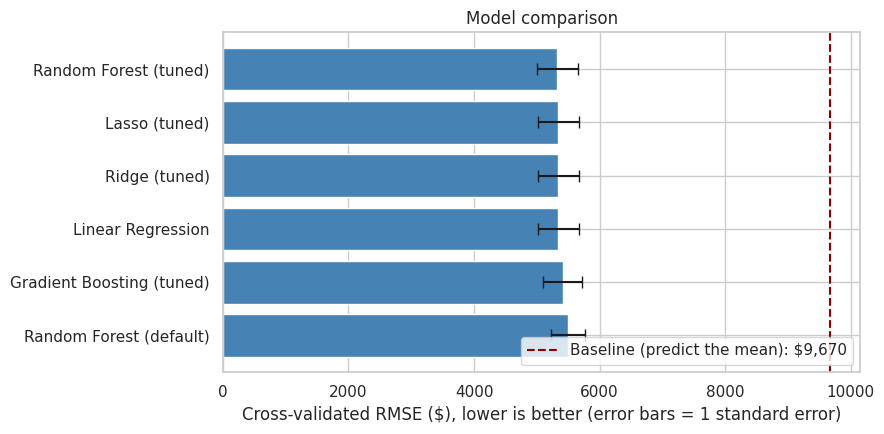

In [10]:
plot_df = comparison.drop(index='Baseline (mean)').sort_values('cv_rmse')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot_df.index, plot_df['cv_rmse'], xerr=plot_df['cv_rmse_se'], color='steelblue', capsize=4)
ax.axvline(comparison.loc['Baseline (mean)', 'cv_rmse'], color='darkred', linestyle='--',
           label=f"Baseline (predict the mean): ${comparison.loc['Baseline (mean)', 'cv_rmse']:,.0f}")
ax.set_xlabel('Cross-validated RMSE ($), lower is better (error bars = 1 standard error)')
ax.set_title('Model comparison')
ax.invert_yaxis()
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figures/model_comparison.png', dpi=150)
plt.show()

**What the comparison shows:**
- **Every model clearly beats the baseline.** Predicting the average misses by about \$9,700 (RMSE). The models cut that to about \$5,300-5,400 and explain about **68-69% of the variation** in adult income (R²). Neighborhood characteristics have real predictive power.
- **The models are essentially tied.** The tuned random forest has the lowest average RMSE, but it beats linear regression by only about \$15, far smaller than one standard error (about \$320). Gradient boosting comes in slightly behind both.
- **Tuning helped the random forest a little** compared with its default settings, which supports tuning. But the more complex tree models don't find much structure that the straight-line model misses. This matches EDA, where the relationships looked mostly linear.

## Step 3: Identify the Final Model

### Choosing with the one-standard-error rule
When several models score within one standard error of the best, the differences could easily be due to which tracts happened to land in each fold. The **one-standard-error rule** says to pick the **simplest** model whose score is within one standard error of the best.

In [11]:
best_name = comparison.drop(index='Baseline (mean)')['cv_rmse'].idxmin()
best_rmse = comparison.loc[best_name, 'cv_rmse']
best_se = comparison.loc[best_name, 'cv_rmse_se']
threshold = best_rmse + best_se

print(f'Lowest CV RMSE: {best_name} (${best_rmse:,.0f})')
print(f'One-standard-error threshold: ${best_rmse:,.0f} + ${best_se:,.0f} = ${threshold:,.0f}')
print()
for name, row in comparison.drop(index='Baseline (mean)').iterrows():
    status = 'within 1 SE' if row['cv_rmse'] <= threshold else 'outside 1 SE'
    print(f"  {name:28s} ${row['cv_rmse']:,.0f}  -> {status}")

Lowest CV RMSE: Random Forest (tuned) ($5,328)
One-standard-error threshold: $5,328 + $322 = $5,651

  Random Forest (tuned)        $5,328  -> within 1 SE
  Lasso (tuned)                $5,342  -> within 1 SE
  Ridge (tuned)                $5,343  -> within 1 SE
  Linear Regression            $5,344  -> within 1 SE
  Gradient Boosting (tuned)    $5,411  -> within 1 SE
  Random Forest (default)      $5,498  -> within 1 SE


### Final model: **Linear Regression**
Linear regression, random forest and gradient boosting all fall within one standard error of the best score, so they perform the same within the uncertainty of the data. Among them, linear regression is the best choice for this project:

| Consideration | Linear Regression | Random Forest / Gradient Boosting |
|---|---|---|
| **Accuracy** | Tied (within 1 SE of the best) | Tied |
| **Interpretability** | Each coefficient is a dollar effect per standard deviation, which is easy to explain to a foundation or community agency | Needs extra tools (feature importance) and gives no direction or dollar size |
| **Computational complexity** | Trains in a fraction of a second, with no tuning | Hundreds of trees, plus a grid search that takes about a minute |
| **Scalability and maintenance** | 11 coefficients and an intercept, easy to retrain each time the Atlas releases new data | Hundreds of stored trees and several settings to re-tune |

The outline's hint says it directly: *the most powerful model isn't always the best one to use.* For a project whose goal is to explain **which** neighborhood characteristics matter, a model that shows the size and direction of each effect is worth more than a tie on accuracy.

### Final check on the test set
The test set has been held back until now. I score all three model types on it for transparency, but **the choice above was made with cross-validation alone**, so the test scores can't influence it.

In [12]:
final_models = {
    'Linear Regression': LinearRegression().fit(X_train, y_train),
    'Random Forest (tuned)': rf_search.best_estimator_,
    'Gradient Boosting (tuned)': gb_search.best_estimator_,
}

test_rows = []
for name, model in final_models.items():
    pred = model.predict(X_test)
    test_rows.append({'model': name,
                      'test_rmse': mean_squared_error(y_test, pred) ** 0.5,
                      'test_mae': mean_absolute_error(y_test, pred),
                      'test_r2': r2_score(y_test, pred)})
test_table = pd.DataFrame(test_rows).set_index('model')
test_table.round({'test_rmse': 0, 'test_mae': 0, 'test_r2': 3})

,test_rmse,test_mae,test_r2
model,,,
Linear Regression,4914.0,3485.0,0.753
Random Forest (tuned),5323.0,3589.0,0.711
Gradient Boosting (tuned),5313.0,3675.0,0.712


**On tracts it has never seen, the final linear regression misses by about \$4,900 (RMSE) and \$3,500 on average (MAE), and explains about 75% of the variation in adult income (R²).** This is in line with, or slightly better than, its cross-validation scores, so there's no sign of overfitting. On this test set it also does slightly better than the two tree-based models, which supports the choice.

### Reviewing the final model

#### Predicted vs. actual income

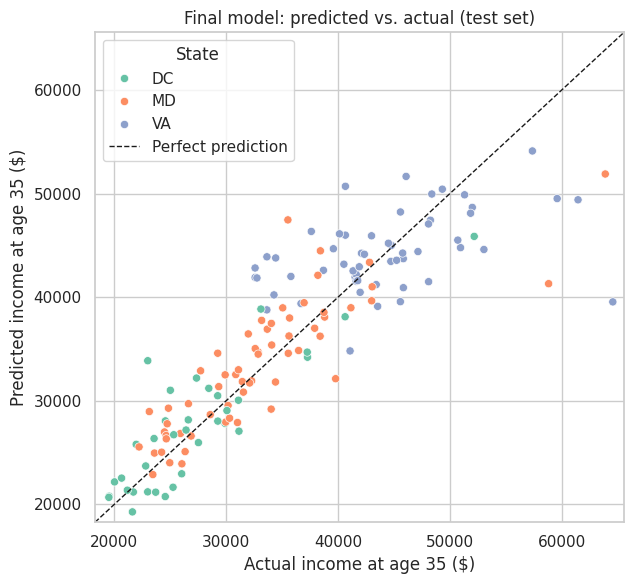

In [13]:
final_model = final_models['Linear Regression']
y_pred = final_model.predict(X_test)

state_test = np.select([X_test['state_MD'] == 1, X_test['state_VA'] == 1], ['MD', 'VA'], default='DC')

fig, ax = plt.subplots(figsize=(6.5, 6))
sns.scatterplot(x=y_test, y=y_pred, hue=state_test, hue_order=['DC', 'MD', 'VA'], palette='Set2', ax=ax, s=35)
lims = [min(y_test.min(), y_pred.min()) - 1000, max(y_test.max(), y_pred.max()) + 1000]
ax.plot(lims, lims, 'k--', linewidth=1, label='Perfect prediction')
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel('Actual income at age 35 ($)')
ax.set_ylabel('Predicted income at age 35 ($)')
ax.set_title('Final model: predicted vs. actual (test set)')
ax.legend(title='State')
plt.tight_layout()
plt.savefig('figures/final_model_predicted_vs_actual.png', dpi=150)
plt.show()

The points follow the diagonal line closely across all three states. The model tends to **under-predict the very highest-income tracts** (points to the right fall below the line), which is common for linear models with a few exceptional neighborhoods.

#### Errors by state

In [14]:
residuals = y_test - y_pred
error_by_state = pd.DataFrame({'state': state_test, 'residual': residuals, 'abs_error': residuals.abs()}) \
    .groupby('state').agg(n_tracts=('residual', 'size'), mean_error=('residual', 'mean'), mae=('abs_error', 'mean')).round(0)
error_by_state

,n_tracts,mean_error,mae
state,,,
DC,35,-280.0,2741.0
MD,61,-491.0,2889.0
VA,55,-179.0,4619.0


The average error (actual minus predicted) is small in every state (a few hundred dollars against incomes in the tens of thousands), so the model doesn't systematically favor or penalize any one jurisdiction. **The typical miss is larger in Virginia** (MAE about \$4,600 vs. about \$2,700-2,900 in DC and Maryland). Virginia has most of the very high-income tracts, which the model tends to under-predict. This is worth mentioning as a limitation in the final report.

#### What drives the predictions: coefficients
Because the numeric features are standardized, each coefficient is the change in predicted adult income (in dollars) for a **one-standard-deviation** increase in that feature, holding the others constant. The state coefficients are the difference from a DC tract with the same characteristics.

Intercept (a DC tract with average characteristics): $34,215


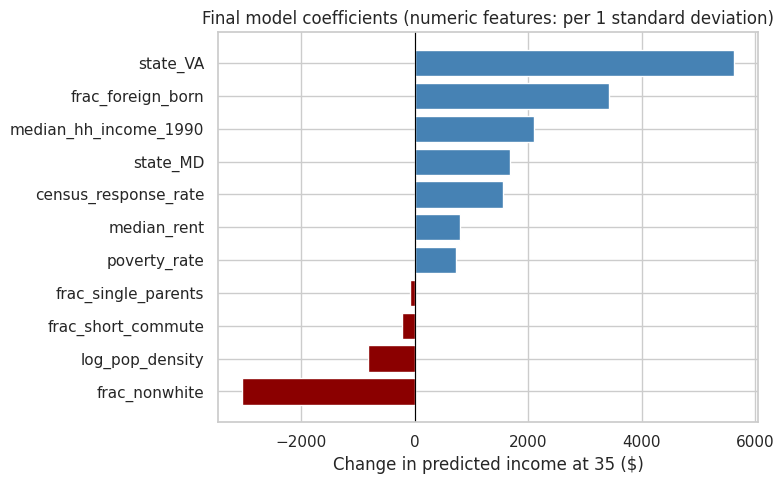

,coefficient_$
frac_nonwhite,-3038.0
log_pop_density,-820.0
frac_short_commute,-217.0
frac_single_parents,-88.0
poverty_rate,731.0
median_rent,807.0
census_response_rate,1552.0
state_MD,1673.0
median_hh_income_1990,2098.0
frac_foreign_born,3422.0


In [15]:
coefs = pd.Series(final_model.coef_, index=X_train.columns).sort_values()
print(f'Intercept (a DC tract with average characteristics): ${final_model.intercept_:,.0f}')

fig, ax = plt.subplots(figsize=(8, 5))
colors = ['darkred' if c < 0 else 'steelblue' for c in coefs]
ax.barh(coefs.index, coefs.values, color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Change in predicted income at 35 ($)')
ax.set_title('Final model coefficients (numeric features: per 1 standard deviation)')
plt.tight_layout()
plt.savefig('figures/final_model_coefficients.png', dpi=150)
plt.show()

coefs.round(0).to_frame('coefficient_$')

**Reading the coefficients:**
- **State has the largest effect.** A Virginia tract is predicted about \$5,600 higher than a DC tract with otherwise identical characteristics, and Maryland about \$1,700 higher. Part of the DC gap remains even after accounting for neighborhood differences.
- **`frac_nonwhite`** (about -\$3,000 per SD) and **`frac_foreign_born`** (about +\$3,400 per SD) are the strongest neighborhood features once everything else is held constant. As noted in EDA, `frac_nonwhite` is a neighborhood measure that likely reflects segregation and unequal investment, not a cause.
- **`median_hh_income_1990`** (+\$2,100) and **`census_response_rate`** (+\$1,600) are positive: neighborhoods that were better off when these children grew up, and with stronger civic participation, see better outcomes.
- **`frac_single_parents` is close to zero, and `poverty_rate` is even slightly positive**, even though EDA showed each one is strongly and negatively related to income on its own. They overlap heavily with `frac_nonwhite` and the income measures, so once those are in the model, the remaining signal is small and can even flip sign. This doesn't mean poverty or family structure don't matter. It means the model can't separate their effects from the features they move with. The final report should present these individual coefficients carefully and lean on the EDA correlations for these two features.

#### Cross-check: which features does the random forest rely on?
**Permutation importance** shuffles one feature at a time on the test set and measures how much worse the predictions get. Agreement between two very different model types makes the findings more trustworthy.

In [16]:
perm = permutation_importance(rf_search.best_estimator_, X_test, y_test, n_repeats=20,
                              random_state=42, scoring='neg_root_mean_squared_error')
rf_importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
rf_importance.round(0).to_frame('RMSE increase when shuffled ($)')

,RMSE increase when shuffled ($)
frac_nonwhite,998.0
median_hh_income_1990,774.0
frac_foreign_born,719.0
state_VA,543.0
median_rent,325.0
frac_single_parents,294.0
census_response_rate,145.0
poverty_rate,63.0
state_MD,38.0
log_pop_density,22.0


The random forest leans most heavily on **`frac_nonwhite`, `median_hh_income_1990`, `frac_foreign_born` and `state_VA`**. These are the same four features with the largest coefficients in the linear model, so two very different approaches tell a consistent story about which neighborhood characteristics matter most.

### Save the final model and its metrics
The final report requires a **model metrics file** listing the final model's features, parameters, hyperparameters and performance. I save it as a text file and a CSV, along with the fitted model.

In [17]:
joblib.dump(final_model, 'models/final_linear_regression.joblib')

metrics_row = test_table.loc['Linear Regression']
cv_row = comparison.loc['Linear Regression']

lines = [
    'FINAL MODEL METRICS',
    'Project: Where You Grow Up Matters: Predicting Adult Income for Low-Income Children in the DC Region',
    '',
    'Model: Linear Regression (scikit-learn LinearRegression, ordinary least squares)',
    f'Parameters: fit_intercept={final_model.fit_intercept}, positive={final_model.positive}',
    'Hyperparameters: none to tune. Ridge and Lasso penalties were tuned with 5-fold CV and gave no improvement.',
    'Model selection: one-standard-error rule on 5-fold cross-validated RMSE (training set only)',
    '',
    f'Target: income_age35 (household income at age 35, $, children of 25th-percentile parents)',
    f'Training tracts: {len(X_train)}   Test tracts: {len(X_test)}',
    f'Features ({X_train.shape[1]}): ' + ', '.join(X_train.columns),
    '',
    'Cross-validation (5-fold, training set):',
    f"  RMSE ${cv_row['cv_rmse']:,.0f} (std ${cv_row['cv_rmse_std']:,.0f})   MAE ${cv_row['cv_mae']:,.0f}   R2 {cv_row['cv_r2']:.3f}",
    'Test set:',
    f"  RMSE ${metrics_row['test_rmse']:,.0f}   MAE ${metrics_row['test_mae']:,.0f}   R2 {metrics_row['test_r2']:.3f}",
    '',
    f'Intercept: {final_model.intercept_:,.2f}',
    'Coefficients ($ per 1 SD for numeric features; $ vs. DC for state dummies):',
] + [f'  {name}: {value:,.2f}' for name, value in pd.Series(final_model.coef_, index=X_train.columns).items()]

with open('models/model_metrics.txt', 'w') as f:
    f.write('\n'.join(lines))

comparison.join(test_table, how='left').round(3).to_csv('models/model_comparison.csv')
print('\n'.join(lines))

FINAL MODEL METRICS
Project: Where You Grow Up Matters: Predicting Adult Income for Low-Income Children in the DC Region

Model: Linear Regression (scikit-learn LinearRegression, ordinary least squares)
Parameters: fit_intercept=True, positive=False
Hyperparameters: none to tune. Ridge and Lasso penalties were tuned with 5-fold CV and gave no improvement.
Model selection: one-standard-error rule on 5-fold cross-validated RMSE (training set only)

Target: income_age35 (household income at age 35, $, children of 25th-percentile parents)
Training tracts: 601   Test tracts: 151
Features (11): median_rent, median_hh_income_1990, poverty_rate, frac_nonwhite, frac_foreign_born, frac_single_parents, log_pop_density, frac_short_commute, census_response_rate, state_MD, state_VA

Cross-validation (5-fold, training set):
  RMSE $5,344 (std $719)   MAE $3,934   R2 0.690
Test set:
  RMSE $4,914   MAE $3,485   R2 0.753

Intercept: 34,214.91
Coefficients ($ per 1 SD for numeric features; $ vs. DC for 

## Summary
- **Problem type:** cross-sectional data, not a time series, so a random split is appropriate. The response is continuous, so this is a **regression** problem, measured with **RMSE** (primary), MAE and R².
- **Models fit on the training set:** a mean baseline, then **Linear Regression** (with tuned Ridge and Lasso variations), **Random Forest** (default, then tuned with `GridSearchCV`) and **Gradient Boosting** (tuned with `GridSearchCV`). All were compared with the same 5-fold cross-validation.
- **Outcomes:** every model beats the baseline (RMSE about \$5,300-5,400 vs. \$9,700, R² about 0.68-0.69). The three model types are statistically tied.
- **Final model: Linear Regression**, chosen by the one-standard-error rule for its interpretability, speed and low maintenance. On the held-out test set: **RMSE about \$4,900, MAE about \$3,500, R² about 0.75**.
- **Key drivers:** state (Virginia and Maryland above DC), `frac_nonwhite`, `frac_foreign_born`, 1990 neighborhood income and census response rate. The random forest's permutation importance broadly agrees.
- **Saved:** `models/final_linear_regression.joblib`, `models/model_metrics.txt`, `models/model_comparison.csv` and 3 new figures in `figures/`.